# DAS7002 Big Data Technologies — PRAC 1

## Task 2: High-Dimensional Exploratory Data Analysis

This notebook performs distributed exploratory analysis on the processed Chicago Crime dataset produced during Task 1.

The analysis uses Apache Spark DataFrames and Spark SQL to investigate temporal, spatial, socioeconomic, and weather-related crime patterns.

The main objectives are to:

- load the processed Parquet datasets generated by the ETL pipeline;
- enrich crime records with Chicago community-area names using a broadcast join;
- investigate temporal and spatial crime distributions;
- calculate rolling crime averages across community areas;
- examine relationships between weather conditions and reported crime;
- use Spark SQL and distributed DataFrame operations throughout the analysis.

The processed Parquet layer is used instead of the original CSV files to avoid repeating ingestion and cleaning operations and to benefit from the columnar and partitioned storage structure established in Task 1.

## 1. Spark and Project Configuration

The exploratory analysis reuses the same local Apache Spark environment configured during Task 1. Hadoop's Windows filesystem utilities are configured before the Spark session is created.

In [1]:
import os
import shutil
from pathlib import Path

os.environ["HADOOP_HOME"] = r"C:\hadoop"
os.environ["PATH"] = r"C:\hadoop\bin;" + os.environ["PATH"]

PROJECT_ROOT = Path(
    r"C:\Users\USER\Desktop\Masters\Big Enterprise\DAS7002"
)

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
FIGURES_DIR = PROJECT_ROOT / "outputs" / "figures"
TABLES_DIR = PROJECT_ROOT / "outputs" / "tables"

print("HADOOP_HOME       :", os.environ.get("HADOOP_HOME"))
print("winutils path     :", shutil.which("winutils"))
print("Processed data dir:", PROCESSED_DIR)

HADOOP_HOME       : C:\hadoop
winutils path     : C:\hadoop\bin\winutils.EXE
Processed data dir: C:\Users\USER\Desktop\Masters\Big Enterprise\DAS7002\data\processed


In [2]:
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql.window import Window

spark = (
    SparkSession.builder
    .appName("DAS7002_PRAC1_Task2_EDA")
    .master("local[*]")
    .config("spark.sql.shuffle.partitions", "8")
    .getOrCreate()
)

print("Spark version      :", spark.version)
print("Application name   :", spark.sparkContext.appName)
print("Master             :", spark.sparkContext.master)
print(
    "Shuffle partitions :",
    spark.conf.get("spark.sql.shuffle.partitions")
)

Spark version      : 3.5.6
Application name   : DAS7002_PRAC1_Task2_EDA
Master             : local[*]
Shuffle partitions : 8


## 2. Loading Processed Parquet Datasets

Task 2 begins from the processed data layer generated in Task 1 rather than re-reading the raw source files.

The partitioned Chicago Crime dataset and the cleaned community, socioeconomic, weather, and police lookup datasets are loaded from Parquet storage.

In [3]:
CRIME_PARQUET_PATH = PROCESSED_DIR / "crime_parquet"
SOCIO_PARQUET_PATH = PROCESSED_DIR / "socioeconomic_parquet"
COMMUNITY_PARQUET_PATH = PROCESSED_DIR / "community_lookup_parquet"
WEATHER_PARQUET_PATH = PROCESSED_DIR / "weather_parquet"
POLICE_PARQUET_PATH = PROCESSED_DIR / "police_lookup_parquet"

crime_df = spark.read.parquet(str(CRIME_PARQUET_PATH))
socio_df = spark.read.parquet(str(SOCIO_PARQUET_PATH))
community_df = spark.read.parquet(str(COMMUNITY_PARQUET_PATH))
weather_df = spark.read.parquet(str(WEATHER_PARQUET_PATH))
police_df = spark.read.parquet(str(POLICE_PARQUET_PATH))

print("Processed Parquet datasets loaded successfully.")

Processed Parquet datasets loaded successfully.


In [4]:
print(f"Crime records          : {crime_df.count():,}")
print(f"Socioeconomic records  : {socio_df.count():,}")
print(f"Community records      : {community_df.count():,}")
print(f"Weather records        : {weather_df.count():,}")
print(f"Police lookup records  : {police_df.count():,}")

Crime records          : 7,784,664
Socioeconomic records  : 77
Community records      : 77
Weather records        : 8,398
Police lookup records  : 23


## 3. Broadcast Join: Community Area Names

The Chicago Crime dataset stores community areas as numeric identifiers, while the community lookup contains the corresponding human-readable community names.

Because the community lookup contains only 77 records, it is sufficiently small to be broadcast to each Spark executor. A broadcast join avoids a large shuffle of the 7.78 million crime records and is therefore more efficient than a standard distributed join for this lookup operation.

This section enriches each crime record with its corresponding community-area name and verifies the join coverage.

In [5]:
from pyspark.sql.functions import broadcast

crime_enriched_df = (
    crime_df
    .join(
        broadcast(community_df),
        crime_df["Community Area"] == community_df["Community_Area"],
        "left"
    )
    .drop("Community_Area")
)

print("Broadcast community join completed.")

Broadcast community join completed.


In [6]:
crime_enriched_df.select(
    "ID",
    "Community Area",
    "Community_Name",
    "Primary Type",
    "Crime_Date"
).show(10, truncate=False)

+-------+--------------+--------------+-------------------+----------+
|ID     |Community Area|Community_Name|Primary Type       |Crime_Date|
+-------+--------------+--------------+-------------------+----------+
|4078534|56            |GARFIELD RIDGE|PROSTITUTION       |2005-05-05|
|4313815|63            |GAGE PARK     |CRIMINAL TRESPASS  |2005-09-11|
|4078543|56            |GARFIELD RIDGE|PROSTITUTION       |2005-05-12|
|4313845|66            |CHICAGO LAWN  |CRIMINAL TRESPASS  |2005-09-11|
|4078687|56            |GARFIELD RIDGE|MOTOR VEHICLE THEFT|2005-06-11|
|4313871|57            |ARCHER HEIGHTS|CRIMINAL TRESPASS  |2005-09-07|
|4078819|70            |ASHBURN       |CRIMINAL DAMAGE    |2005-06-14|
|4313989|56            |GARFIELD RIDGE|CRIMINAL TRESPASS  |2005-09-11|
|4078831|63            |GAGE PARK     |CRIMINAL DAMAGE    |2005-06-16|
|4314051|66            |CHICAGO LAWN  |MOTOR VEHICLE THEFT|2005-09-18|
+-------+--------------+--------------+-------------------+----------+
only s

In [7]:
community_join_validation = (
    crime_enriched_df
    .agg(
        F.count("*").alias("Total_Crime_Records"),
        F.sum(
            F.when(F.col("Community_Name").isNull(), 1).otherwise(0)
        ).alias("Missing_Community_Name"),
        F.sum(
            F.when(F.col("Community_Name").isNotNull(), 1).otherwise(0)
        ).alias("Matched_Community_Name")
    )
)

community_join_validation.show(truncate=False)

+-------------------+----------------------+----------------------+
|Total_Crime_Records|Missing_Community_Name|Matched_Community_Name|
+-------------------+----------------------+----------------------+
|7784664            |613552                |7171112               |
+-------------------+----------------------+----------------------+



### 3.1 Broadcast Join Interpretation

The broadcast join successfully enriched the Chicago Crime dataset with human-readable community-area names.

Of the 7,784,664 crime records, 7,171,112 were matched to a community name, while 613,552 records remained unmatched. Most unmatched records correspond to incidents where the source crime data does not contain a valid community-area identifier, rather than a failure of the lookup itself.

The formatted Spark execution plan confirms the use of a `BroadcastHashJoin` and `BroadcastExchange`. Because the community lookup contains only 77 records, Spark distributes this small lookup to the available executors and avoids shuffling the much larger crime dataset.

This join strategy is therefore appropriate for enriching the large crime dataset with small reference data and demonstrates an optimisation commonly used in distributed analytical pipelines.

In [8]:
crime_enriched_df.explain(mode="formatted")

== Physical Plan ==
AdaptiveSparkPlan (7)
+- Project (6)
   +- BroadcastHashJoin LeftOuter BuildRight (5)
      :- Scan parquet  (1)
      +- BroadcastExchange (4)
         +- Filter (3)
            +- Scan parquet  (2)


(1) Scan parquet 
Output [30]: [ID#0L, Case Number#1, Crime_Timestamp#2, Crime_Date#3, Block#4, IUCR#5, Primary Type#6, Description#7, Location Description#8, Arrest#9, Domestic#10, Beat#11, Ward#12, Community Area#13, FBI Code#14, X Coordinate#15, Y Coordinate#16, Updated_Timestamp#17, Latitude#18, Longitude#19, Location#20, Crime_Year#21, Crime_Month#22, Crime_Month_Name#23, Crime_Day#24, Crime_Day_Of_Week#25, Crime_Hour#26, Is_Weekend#27, Year#28, District#29]
Batched: true
Location: InMemoryFileIndex [file:/C:/Users/USER/Desktop/Masters/Big Enterprise/DAS7002/data/processed/crime_parquet]
ReadSchema: struct<ID:bigint,Case Number:string,Crime_Timestamp:timestamp,Crime_Date:date,Block:string,IUCR:string,Primary Type:string,Description:string,Location Description:str

## 4. Temporal Crime Analysis Using Spark SQL

Temporal analysis is first performed at annual level to examine how reported crime volume changes across the 2001–2023 study period.

The enriched crime DataFrame is registered as a temporary Spark SQL view, allowing distributed SQL queries to be executed directly against the processed dataset.

In [9]:
crime_enriched_df.createOrReplaceTempView("crime_enriched")

print("Spark SQL view 'crime_enriched' created successfully.")

Spark SQL view 'crime_enriched' created successfully.


### 4.1 Annual Crime Trend

Annual crime counts provide an overview of long-term changes in recorded crime across Chicago.

Spark SQL is used to group the complete dataset by year and calculate the number of reported incidents in each year.

In [10]:
annual_crime_sql = spark.sql("""
    SELECT
        Year,
        COUNT(*) AS Crime_Count
    FROM crime_enriched
    WHERE Year IS NOT NULL
    GROUP BY Year
    ORDER BY Year
""")

annual_crime_sql.show(30, truncate=False)

+----+-----------+
|Year|Crime_Count|
+----+-----------+
|2001|485878     |
|2002|486802     |
|2003|475979     |
|2004|469421     |
|2005|453771     |
|2006|448174     |
|2007|437084     |
|2008|427167     |
|2009|392819     |
|2010|370496     |
|2011|351964     |
|2012|336262     |
|2013|307468     |
|2014|275731     |
|2015|264755     |
|2016|269786     |
|2017|269071     |
|2018|268773     |
|2019|261245     |
|2020|212092     |
|2021|208571     |
|2022|238215     |
|2023|73140      |
+----+-----------+



In [11]:
annual_crime_sql.orderBy(
    F.desc("Crime_Count")
).show(5, truncate=False)

annual_crime_sql.orderBy(
    F.asc("Crime_Count")
).show(5, truncate=False)

+----+-----------+
|Year|Crime_Count|
+----+-----------+
|2002|486802     |
|2001|485878     |
|2003|475979     |
|2004|469421     |
|2005|453771     |
+----+-----------+
only showing top 5 rows

+----+-----------+
|Year|Crime_Count|
+----+-----------+
|2023|73140      |
|2021|208571     |
|2020|212092     |
|2022|238215     |
|2019|261245     |
+----+-----------+
only showing top 5 rows



### 4.1.1 Annual Trend Interpretation

The annual distribution shows a substantial long-term decline in recorded crime across the study period.

The highest annual count occurs in 2002, with 486,802 reported incidents, followed closely by 2001 with 485,878 incidents. Crime volumes then generally decline over the following two decades, reaching 208,571 incidents in 2021.

The trend is not completely uniform. For example, small increases are visible in 2016 and 2022, indicating that the overall decline contains shorter-term fluctuations.

The 2023 value of 73,140 incidents should not be compared directly with complete calendar years because the crime dataset contains records only up to 21 April 2023. It therefore represents a partial year rather than evidence of an exceptionally large annual reduction.

Overall, the results indicate a pronounced long-term reduction in reported crime volume, while also demonstrating the importance of considering temporal coverage before interpreting annual aggregates.

### 4.2 Annual Crime Trend Visualisation

The annual Spark SQL result is converted to a small Pandas DataFrame only after aggregation. This is computationally appropriate because Spark performs the distributed aggregation across the full crime dataset first, while only the resulting annual summary is collected locally for visualisation.

Because 2023 contains only partial-year observations, the primary long-term visualisation focuses on complete calendar years from 2001 to 2022.

In [12]:
annual_complete_df = (
    annual_crime_sql
    .filter(F.col("Year") <= 2022)
    .orderBy("Year")
)

annual_complete_pd = annual_complete_df.toPandas()

annual_complete_pd

,Year,Crime_Count
0,2001,485878
1,2002,486802
2,2003,475979
3,2004,469421
4,2005,453771
5,2006,448174
6,2007,437084
7,2008,427167
8,2009,392819
9,2010,370496


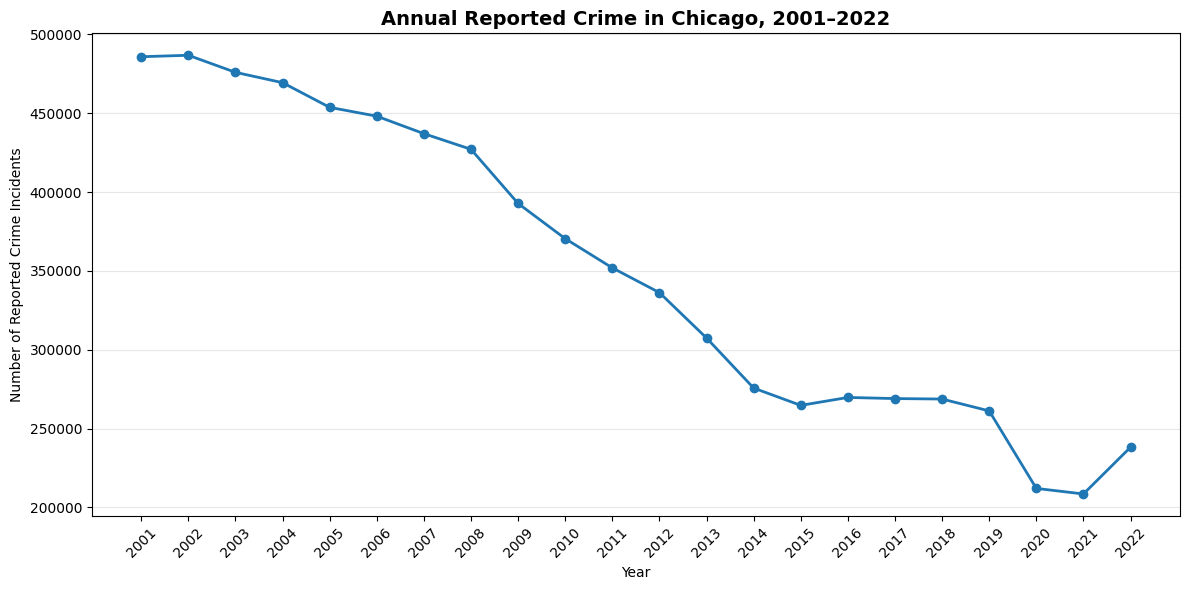

Figure saved to: C:\Users\USER\Desktop\Masters\Big Enterprise\DAS7002\outputs\figures\task2_annual_crime_trend_2001_2022.png


In [13]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.plot(
    annual_complete_pd["Year"],
    annual_complete_pd["Crime_Count"],
    marker="o",
    linewidth=2
)

plt.title(
    "Annual Reported Crime in Chicago, 2001–2022",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Year")
plt.ylabel("Number of Reported Crime Incidents")

plt.xticks(
    annual_complete_pd["Year"],
    rotation=45
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

ANNUAL_FIGURE_PATH = (
    FIGURES_DIR / "task2_annual_crime_trend_2001_2022.png"
)

plt.savefig(
    ANNUAL_FIGURE_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure saved to:", ANNUAL_FIGURE_PATH)

In [14]:
crime_2001 = (
    annual_crime_sql
    .filter(F.col("Year") == 2001)
    .select("Crime_Count")
    .first()[0]
)

crime_2022 = (
    annual_crime_sql
    .filter(F.col("Year") == 2022)
    .select("Crime_Count")
    .first()[0]
)

percentage_change = (
    (crime_2022 - crime_2001) / crime_2001
) * 100

print(f"Crime count in 2001 : {crime_2001:,}")
print(f"Crime count in 2022 : {crime_2022:,}")
print(
    f"Percentage change   : {percentage_change:.2f}%"
)

Crime count in 2001 : 485,878
Crime count in 2022 : 238,215
Percentage change   : -50.97%


### 4.3 Monthly Crime Seasonality

Monthly crime patterns are analysed to identify recurring seasonal variation in reported incidents.

To avoid distortion from the incomplete 2023 observation period, this analysis uses complete calendar years from 2001 to 2022 only.

Spark SQL is used to aggregate crime records by calendar month across the complete-year study period.

In [15]:
monthly_crime_sql = spark.sql("""
    SELECT
        Crime_Month,
        Crime_Month_Name,
        COUNT(*) AS Crime_Count
    FROM crime_enriched
    WHERE Year BETWEEN 2001 AND 2022
      AND Crime_Month IS NOT NULL
    GROUP BY Crime_Month, Crime_Month_Name
    ORDER BY Crime_Month
""")

monthly_crime_sql.show(12, truncate=False)

+-----------+----------------+-----------+
|Crime_Month|Crime_Month_Name|Crime_Count|
+-----------+----------------+-----------+
|1          |January         |601062     |
|2          |February        |529307     |
|3          |March           |629597     |
|4          |April           |627072     |
|5          |May             |682819     |
|6          |June            |681640     |
|7          |July            |717118     |
|8          |August          |710301     |
|9          |September       |668097     |
|10         |October         |676128     |
|11         |November        |608818     |
|12         |December        |579565     |
+-----------+----------------+-----------+



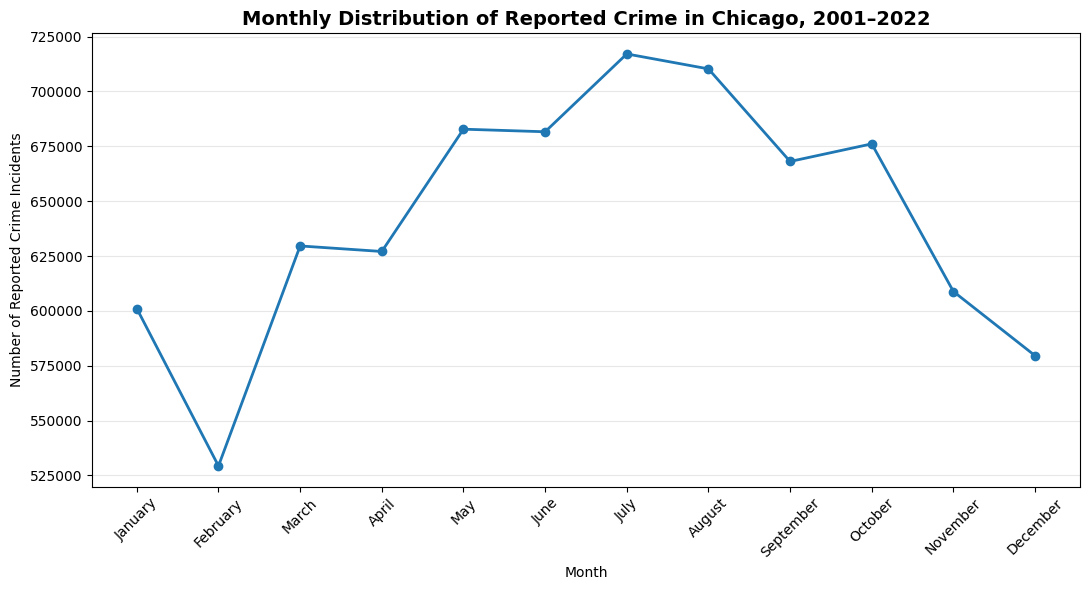

Figure saved to: C:\Users\USER\Desktop\Masters\Big Enterprise\DAS7002\outputs\figures\task2_monthly_crime_seasonality_2001_2022.png


In [17]:
monthly_crime_pd = monthly_crime_sql.toPandas()

plt.figure(figsize=(11, 6))

plt.plot(
    monthly_crime_pd["Crime_Month_Name"],
    monthly_crime_pd["Crime_Count"],
    marker="o",
    linewidth=2
)

plt.title(
    "Monthly Distribution of Reported Crime in Chicago, 2001–2022",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Month")
plt.ylabel("Number of Reported Crime Incidents")

plt.xticks(rotation=45)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

MONTHLY_FIGURE_PATH = (
    FIGURES_DIR / "task2_monthly_crime_seasonality_2001_2022.png"
)

plt.savefig(
    MONTHLY_FIGURE_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure saved to:", MONTHLY_FIGURE_PATH)

### 4.3.1 Monthly Seasonality Interpretation

The monthly distribution demonstrates a clear seasonal pattern in reported crime between 2001 and 2022.

Raw incident totals are highest during the warmer middle months of the year, particularly July and August, while February records the lowest cumulative total.

However, monthly totals are influenced by calendar length because months contain different numbers of days. Therefore, the raw monthly distribution is interpreted as incident volume rather than a directly comparable crime rate.

To improve comparability, an additional average-daily analysis is used to examine whether the seasonal pattern remains after accounting for differences in month length.

The observed pattern indicates an association between season and reported crime activity, but it should not be interpreted as evidence that temperature itself causes changes in crime. Weather relationships are examined separately using observed temperature and precipitation data.

### 4.3.2 Average Daily Crime by Month

Monthly incident totals are influenced by the number of calendar days in each month. For example, February contains fewer days than July or August, which can partially reduce its cumulative incident count even if the average daily crime level is similar.

To account for this, the monthly analysis is supplemented with an average daily crime measure. Daily crime counts are first calculated for each calendar date between 2001 and 2022 and are then averaged by month.

This provides a more comparable measure of seasonal crime activity across months with different lengths.

In [18]:
daily_monthly_crime_df = spark.sql("""
    SELECT
        Crime_Date,
        Crime_Month,
        Crime_Month_Name,
        COUNT(*) AS Daily_Crime_Count
    FROM crime_enriched
    WHERE Year BETWEEN 2001 AND 2022
      AND Crime_Date IS NOT NULL
      AND Crime_Month IS NOT NULL
    GROUP BY
        Crime_Date,
        Crime_Month,
        Crime_Month_Name
""")

In [19]:
monthly_daily_average_df = (
    daily_monthly_crime_df
    .groupBy(
        "Crime_Month",
        "Crime_Month_Name"
    )
    .agg(
        F.round(
            F.avg("Daily_Crime_Count"),
            2
        ).alias("Average_Daily_Crime")
    )
    .orderBy("Crime_Month")
)

monthly_daily_average_df.show(
    12,
    truncate=False
)

+-----------+----------------+-------------------+
|Crime_Month|Crime_Month_Name|Average_Daily_Crime|
+-----------+----------------+-------------------+
|1          |January         |881.32             |
|2          |February        |852.35             |
|3          |March           |923.16             |
|4          |April           |950.11             |
|5          |May             |1001.2             |
|6          |June            |1032.79            |
|7          |July            |1051.49            |
|8          |August          |1041.5             |
|9          |September       |1012.27            |
|10         |October         |991.39             |
|11         |November        |922.45             |
|12         |December        |849.8              |
+-----------+----------------+-------------------+



### 4.3.3 Average-Daily Seasonality Interpretation

The average-daily analysis confirms that the seasonal pattern is not explained solely by differences in month length.

July records the highest average daily crime volume at approximately 1,051.49 incidents per day, followed by August at 1,041.50 and June at 1,032.79. December records the lowest average at approximately 849.80 incidents per day, followed closely by February at 852.35.

The persistence of higher average daily crime levels during late spring and summer indicates a genuine seasonal pattern in reported crime activity across the study period. However, this remains an observational association rather than evidence of a causal effect of temperature or season.

The subsequent weather analysis therefore examines observed temperature and precipitation directly to assess whether meteorological conditions are statistically associated with daily crime volume.

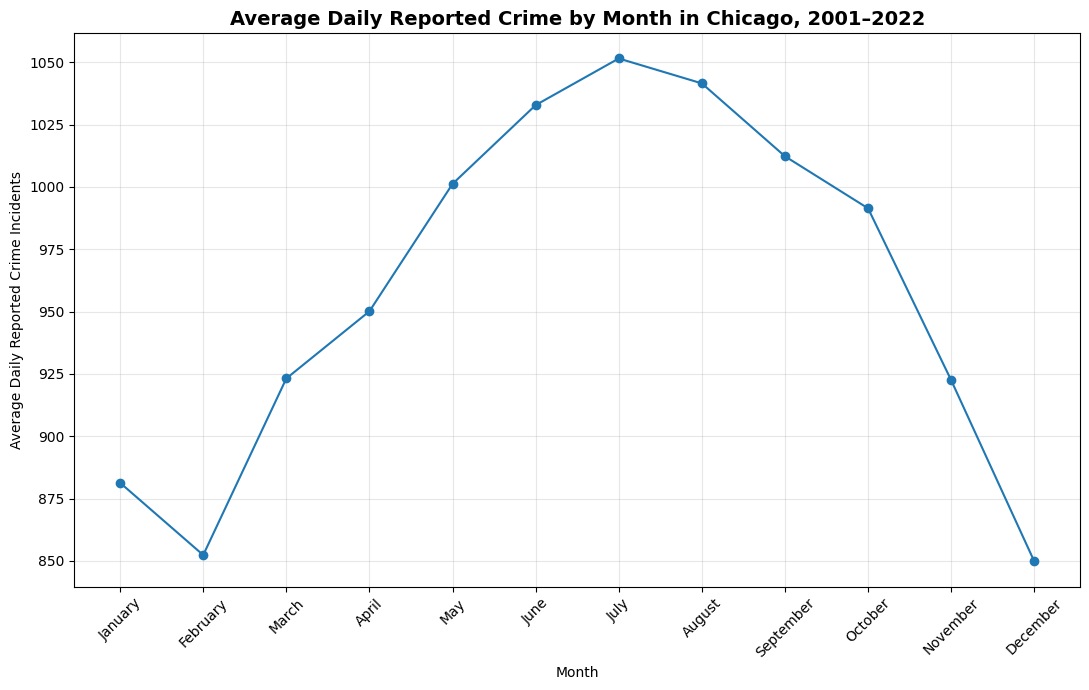

Figure saved to: C:\Users\USER\Desktop\Masters\Big Enterprise\DAS7002\outputs\figures\task2_average_daily_crime_by_month_2001_2022.png


In [20]:
monthly_daily_average_pd = (
    monthly_daily_average_df
    .orderBy("Crime_Month")
    .toPandas()
)

plt.figure(figsize=(11, 7))

plt.plot(
    monthly_daily_average_pd["Crime_Month_Name"],
    monthly_daily_average_pd["Average_Daily_Crime"],
    marker="o"
)

plt.title(
    "Average Daily Reported Crime by Month in Chicago, 2001–2022",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Month")
plt.ylabel("Average Daily Reported Crime Incidents")

plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()

MONTHLY_DAILY_FIGURE_PATH = (
    FIGURES_DIR
    / "task2_average_daily_crime_by_month_2001_2022.png"
)

plt.savefig(
    MONTHLY_DAILY_FIGURE_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "Figure saved to:",
    MONTHLY_DAILY_FIGURE_PATH
)

### 4.4 Day-of-Week Crime Distribution

The analysis is extended to the day-of-week dimension to determine whether reported crime activity varies systematically across the weekly cycle.

As with the monthly analysis, only complete calendar years from 2001 to 2022 are used to avoid distortion from the partial 2023 dataset.

In [21]:
weekday_crime_sql = spark.sql("""
    SELECT
        Crime_Day_Of_Week,
        COUNT(*) AS Crime_Count
    FROM crime_enriched
    WHERE Year BETWEEN 2001 AND 2022
      AND Crime_Day_Of_Week IS NOT NULL
    GROUP BY Crime_Day_Of_Week
""")

weekday_crime_sql.show(truncate=False)

+-----------------+-----------+
|Crime_Day_Of_Week|Crime_Count|
+-----------------+-----------+
|Friday           |1159123    |
|Monday           |1089825    |
|Sunday           |1048019    |
|Thursday         |1098264    |
|Saturday         |1104749    |
|Wednesday        |1109378    |
|Tuesday          |1102166    |
+-----------------+-----------+



In [22]:
weekday_ordered_df = (
    weekday_crime_sql
    .withColumn(
        "Day_Order",
        F.when(F.col("Crime_Day_Of_Week") == "Monday", 1)
         .when(F.col("Crime_Day_Of_Week") == "Tuesday", 2)
         .when(F.col("Crime_Day_Of_Week") == "Wednesday", 3)
         .when(F.col("Crime_Day_Of_Week") == "Thursday", 4)
         .when(F.col("Crime_Day_Of_Week") == "Friday", 5)
         .when(F.col("Crime_Day_Of_Week") == "Saturday", 6)
         .when(F.col("Crime_Day_Of_Week") == "Sunday", 7)
    )
    .orderBy("Day_Order")
)

weekday_ordered_df.select(
    "Crime_Day_Of_Week",
    "Crime_Count"
).show(7, truncate=False)

+-----------------+-----------+
|Crime_Day_Of_Week|Crime_Count|
+-----------------+-----------+
|Monday           |1089825    |
|Tuesday          |1102166    |
|Wednesday        |1109378    |
|Thursday         |1098264    |
|Friday           |1159123    |
|Saturday         |1104749    |
|Sunday           |1048019    |
+-----------------+-----------+



In [23]:
weekday_crime_sql.orderBy(
    F.desc("Crime_Count")
).show(3, truncate=False)

weekday_crime_sql.orderBy(
    F.asc("Crime_Count")
).show(3, truncate=False)

+-----------------+-----------+
|Crime_Day_Of_Week|Crime_Count|
+-----------------+-----------+
|Friday           |1159123    |
|Wednesday        |1109378    |
|Saturday         |1104749    |
+-----------------+-----------+
only showing top 3 rows

+-----------------+-----------+
|Crime_Day_Of_Week|Crime_Count|
+-----------------+-----------+
|Sunday           |1048019    |
|Monday           |1089825    |
|Thursday         |1098264    |
+-----------------+-----------+
only showing top 3 rows



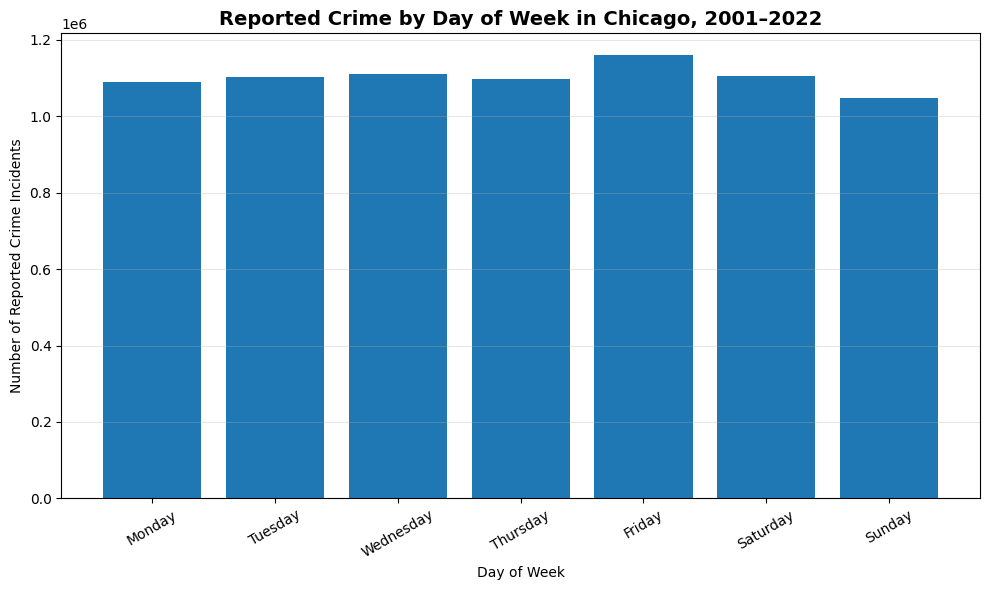

Figure saved to: C:\Users\USER\Desktop\Masters\Big Enterprise\DAS7002\outputs\figures\task2_weekday_crime_distribution_2001_2022.png


In [24]:
weekday_crime_pd = (
    weekday_ordered_df
    .select("Crime_Day_Of_Week", "Crime_Count")
    .toPandas()
)

plt.figure(figsize=(10, 6))

plt.bar(
    weekday_crime_pd["Crime_Day_Of_Week"],
    weekday_crime_pd["Crime_Count"]
)

plt.title(
    "Reported Crime by Day of Week in Chicago, 2001–2022",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Day of Week")
plt.ylabel("Number of Reported Crime Incidents")

plt.xticks(rotation=30)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

WEEKDAY_FIGURE_PATH = (
    FIGURES_DIR / "task2_weekday_crime_distribution_2001_2022.png"
)

plt.savefig(
    WEEKDAY_FIGURE_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure saved to:", WEEKDAY_FIGURE_PATH)

### 4.4.1 Day-of-Week Interpretation

Reported crime is distributed fairly evenly across the week, although some differences are visible.

Friday records the highest cumulative crime count, with 1,159,123 incidents, followed by Wednesday and Saturday. Sunday records the lowest total, with 1,048,019 incidents.

The difference between weekdays is smaller than the seasonal differences observed across months, suggesting that weekly variation exists but is less pronounced than monthly seasonality.

Friday's higher total may reflect changes in social activity, mobility, and routine behaviour toward the end of the working week. However, this pattern is descriptive and should not be interpreted as evidence of causation.

### 4.5 Hour-of-Day Crime Distribution

Hourly analysis is used to identify whether reported crime activity is concentrated during particular periods of the day.

Crime records from complete calendar years between 2001 and 2022 are aggregated by the derived `Crime_Hour` field using Spark SQL.

In [25]:
hourly_crime_sql = spark.sql("""
    SELECT
        Crime_Hour,
        COUNT(*) AS Crime_Count
    FROM crime_enriched
    WHERE Year BETWEEN 2001 AND 2022
      AND Crime_Hour IS NOT NULL
    GROUP BY Crime_Hour
    ORDER BY Crime_Hour
""")

hourly_crime_sql.show(24, truncate=False)

+----------+-----------+
|Crime_Hour|Crime_Count|
+----------+-----------+
|0         |439349     |
|1         |244519     |
|2         |206131     |
|3         |166698     |
|4         |126572     |
|5         |105526     |
|6         |123295     |
|7         |176053     |
|8         |260940     |
|9         |333431     |
|10        |326907     |
|11        |342016     |
|12        |442607     |
|13        |366225     |
|14        |388910     |
|15        |410110     |
|16        |388977     |
|17        |395761     |
|18        |421494     |
|19        |434656     |
|20        |433187     |
|21        |420456     |
|22        |413760     |
|23        |343944     |
+----------+-----------+



In [26]:
hourly_crime_sql = spark.sql("""
    SELECT
        Crime_Hour,
        COUNT(*) AS Crime_Count
    FROM crime_enriched
    WHERE Year BETWEEN 2001 AND 2022
      AND Crime_Hour IS NOT NULL
    GROUP BY Crime_Hour
    ORDER BY Crime_Hour
""")

hourly_crime_sql.show(24, truncate=False)

+----------+-----------+
|Crime_Hour|Crime_Count|
+----------+-----------+
|0         |439349     |
|1         |244519     |
|2         |206131     |
|3         |166698     |
|4         |126572     |
|5         |105526     |
|6         |123295     |
|7         |176053     |
|8         |260940     |
|9         |333431     |
|10        |326907     |
|11        |342016     |
|12        |442607     |
|13        |366225     |
|14        |388910     |
|15        |410110     |
|16        |388977     |
|17        |395761     |
|18        |421494     |
|19        |434656     |
|20        |433187     |
|21        |420456     |
|22        |413760     |
|23        |343944     |
+----------+-----------+



In [27]:
hourly_crime_sql.orderBy(
    F.desc("Crime_Count")
).show(5, truncate=False)

hourly_crime_sql.orderBy(
    F.asc("Crime_Count")
).show(5, truncate=False)

+----------+-----------+
|Crime_Hour|Crime_Count|
+----------+-----------+
|12        |442607     |
|0         |439349     |
|19        |434656     |
|20        |433187     |
|18        |421494     |
+----------+-----------+
only showing top 5 rows

+----------+-----------+
|Crime_Hour|Crime_Count|
+----------+-----------+
|5         |105526     |
|6         |123295     |
|4         |126572     |
|3         |166698     |
|7         |176053     |
+----------+-----------+
only showing top 5 rows



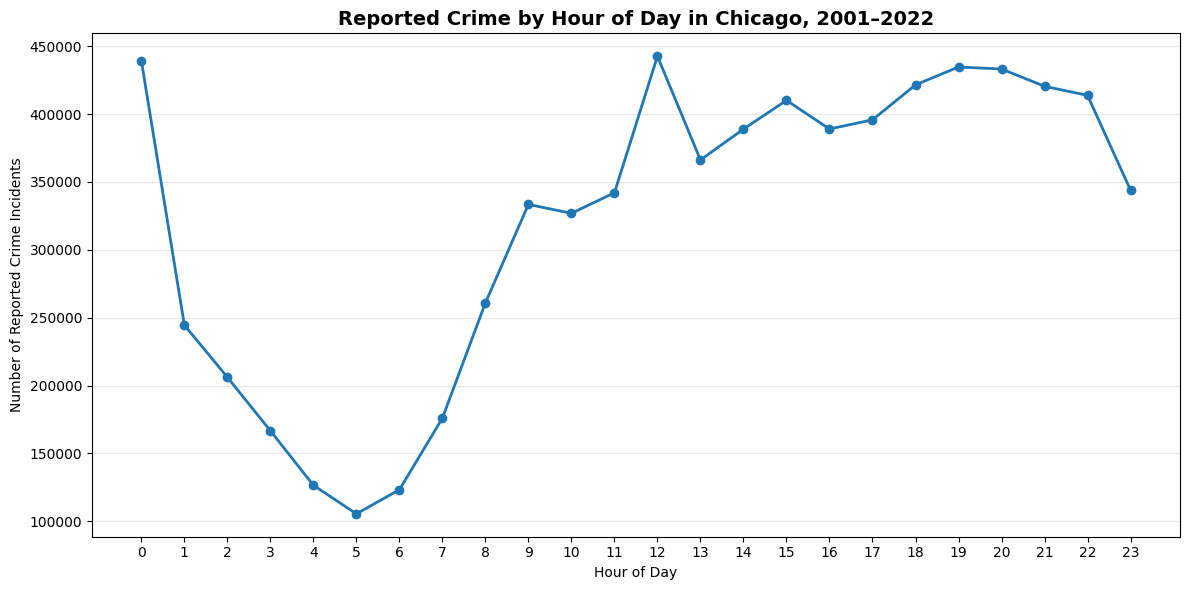

Figure saved to: C:\Users\USER\Desktop\Masters\Big Enterprise\DAS7002\outputs\figures\task2_hourly_crime_distribution_2001_2022.png


In [28]:
hourly_crime_pd = hourly_crime_sql.toPandas()

plt.figure(figsize=(12, 6))

plt.plot(
    hourly_crime_pd["Crime_Hour"],
    hourly_crime_pd["Crime_Count"],
    marker="o",
    linewidth=2
)

plt.title(
    "Reported Crime by Hour of Day in Chicago, 2001–2022",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Hour of Day")
plt.ylabel("Number of Reported Crime Incidents")

plt.xticks(range(0, 24))

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

HOURLY_FIGURE_PATH = (
    FIGURES_DIR / "task2_hourly_crime_distribution_2001_2022.png"
)

plt.savefig(
    HOURLY_FIGURE_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure saved to:", HOURLY_FIGURE_PATH)

### 4.5.1 Hour-of-Day Interpretation

The hourly distribution reveals a pronounced daily pattern in reported crime.

Crime activity is lowest during the early morning period, particularly between 04:00 and 06:00. The minimum occurs at 05:00, with 105,526 reported incidents.

Reported crime rises sharply after the early morning period and remains comparatively high from the afternoon into the evening. The highest cumulative count occurs at 12:00 with 442,607 incidents, followed closely by midnight, 19:00, and 20:00.

The concentration of incidents during daytime and evening hours suggests that crime volume varies substantially across the daily activity cycle. However, these results describe the timing of reported incidents and should not be interpreted as evidence that time of day itself causes crime.

The unusually high counts at exactly 00:00 and 12:00 may also reflect reporting or timestamp-recording practices for some incidents, so these peaks should be interpreted with caution.

## 5. Spatial Crime Distribution Across Community Areas

Spatial exploratory analysis is used to examine how reported crime varies across Chicago's 77 community areas.

Only records with successfully matched community-area names are used in this section. This avoids treating records with missing community identifiers as valid spatial observations.

The analysis first compares cumulative crime volumes across community areas before moving to rolling averages and socioeconomic relationships.

In [29]:
community_crime_sql = spark.sql("""
    SELECT
        `Community Area` AS Community_Area,
        Community_Name,
        COUNT(*) AS Crime_Count
    FROM crime_enriched
    WHERE Year BETWEEN 2003 AND 2022
      AND Community_Name IS NOT NULL
    GROUP BY `Community Area`, Community_Name
    ORDER BY Crime_Count DESC
""")

community_crime_sql.show(20, truncate=False)

+--------------+----------------------+-----------+
|Community_Area|Community_Name        |Crime_Count|
+--------------+----------------------+-----------+
|25            |AUSTIN                |423261     |
|8             |NEAR NORTH SIDE       |237008     |
|43            |SOUTH SHORE           |222844     |
|23            |HUMBOLDT PARK         |210691     |
|28            |NEAR WEST SIDE        |203118     |
|29            |NORTH LAWNDALE        |198995     |
|24            |WEST TOWN             |195557     |
|67            |WEST ENGLEWOOD        |193457     |
|71            |AUBURN GRESHAM        |192101     |
|49            |ROSELAND              |179949     |
|68            |ENGLEWOOD             |175978     |
|69            |GREATER GRAND CROSSING|168328     |
|32            |LOOP                  |167911     |
|66            |CHICAGO LAWN          |164848     |
|44            |CHATHAM               |149338     |
|22            |LOGAN SQUARE          |137864     |
|6          

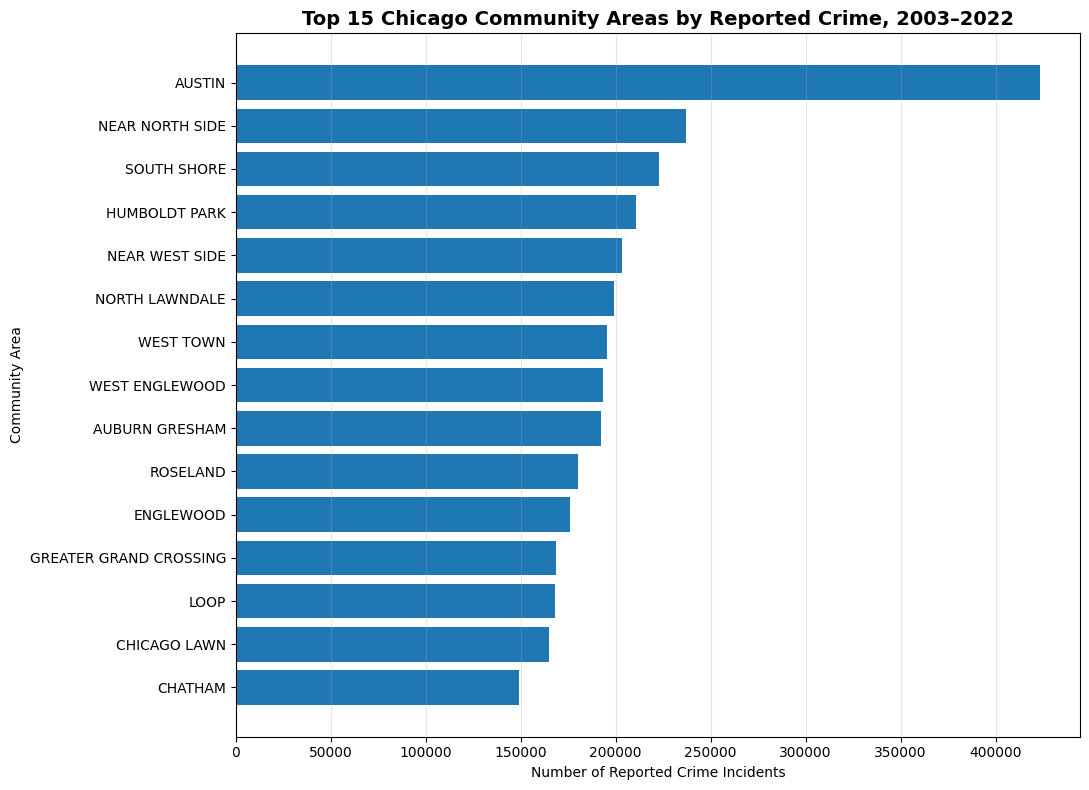

Figure saved to: C:\Users\USER\Desktop\Masters\Big Enterprise\DAS7002\outputs\figures\task2_top15_community_crime_2003_2022.png


In [30]:
top_15_community_pd = (
    community_crime_sql
    .orderBy(F.desc("Crime_Count"))
    .limit(15)
    .toPandas()
)

plt.figure(figsize=(11, 8))

plt.barh(
    top_15_community_pd["Community_Name"][::-1],
    top_15_community_pd["Crime_Count"][::-1]
)

plt.title(
    "Top 15 Chicago Community Areas by Reported Crime, 2003–2022",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Number of Reported Crime Incidents")
plt.ylabel("Community Area")

plt.grid(
    axis="x",
    alpha=0.3
)

plt.tight_layout()

COMMUNITY_FIGURE_PATH = (
    FIGURES_DIR
    / "task2_top15_community_crime_2003_2022.png"
)

plt.savefig(
    COMMUNITY_FIGURE_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "Figure saved to:",
    COMMUNITY_FIGURE_PATH
)

### 5.1.1 Community-Area Distribution Interpretation

Reported crime is distributed unevenly across Chicago's community areas.

This spatial comparison is restricted to 2003–2022 because community-area coverage is incomplete in 2001 and 2002. From 2003 onward, community-area coverage exceeds 99.9%, providing a substantially more reliable basis for spatial comparison.

Austin records the highest cumulative reported-crime volume during the analysed period, with several other community areas also exhibiting comparatively high incident totals.

These results demonstrate clear spatial concentration in reported crime. However, cumulative incident counts should not automatically be interpreted as per-capita crime risk because community areas differ in population size, land use, commercial activity, and population movement.

The analysis therefore describes the spatial distribution of reported incidents rather than individual exposure to crime.

### 5.2 Rolling Average Crime Trends Across Community Areas

Annual crime volumes can fluctuate from year to year, making longer-term spatial trends difficult to identify from raw yearly counts alone.

A three-year rolling average is therefore calculated separately for each Chicago community area. Spark window functions are used to average the current year and the preceding two years within each community-area partition.

This smoothing approach reduces short-term variation while preserving changes in the longer-term trajectory of reported crime.

Because annual population estimates are not available in the current project datasets, this analysis uses annual incident counts rather than population-normalised crime rates. The results should therefore be interpreted as rolling average crime activity rather than per-capita risk.

In [31]:
community_yearly_df = spark.sql("""
    SELECT
        `Community Area` AS Community_Area,
        Community_Name,
        Year,
        COUNT(*) AS Annual_Crime_Count
    FROM crime_enriched
    WHERE Year BETWEEN 2001 AND 2022
      AND Community_Name IS NOT NULL
    GROUP BY
        `Community Area`,
        Community_Name,
        Year
    ORDER BY
        Community_Area,
        Year
""")

community_yearly_df.show(20, truncate=False)

+--------------+--------------+----+------------------+
|Community_Area|Community_Name|Year|Annual_Crime_Count|
+--------------+--------------+----+------------------+
|1             |ROGERS PARK   |2001|58                |
|1             |ROGERS PARK   |2002|6106              |
|1             |ROGERS PARK   |2003|7685              |
|1             |ROGERS PARK   |2004|7610              |
|1             |ROGERS PARK   |2005|7531              |
|1             |ROGERS PARK   |2006|7207              |
|1             |ROGERS PARK   |2007|6809              |
|1             |ROGERS PARK   |2008|6500              |
|1             |ROGERS PARK   |2009|5963              |
|1             |ROGERS PARK   |2010|5579              |
|1             |ROGERS PARK   |2011|5126              |
|1             |ROGERS PARK   |2012|4930              |
|1             |ROGERS PARK   |2013|4440              |
|1             |ROGERS PARK   |2014|3810              |
|1             |ROGERS PARK   |2015|3599        

In [32]:
from pyspark.sql.window import Window

community_rolling_window = (
    Window
    .partitionBy("Community_Area")
    .orderBy("Year")
    .rowsBetween(-2, 0)
)

In [33]:
community_rolling_df = (
    community_yearly_df
    .withColumn(
        "Rolling_3Year_Avg",
        F.avg("Annual_Crime_Count").over(
            community_rolling_window
        )
    )
)

community_rolling_df.show(25, truncate=False)

+--------------+--------------+----+------------------+------------------+
|Community_Area|Community_Name|Year|Annual_Crime_Count|Rolling_3Year_Avg |
+--------------+--------------+----+------------------+------------------+
|1             |ROGERS PARK   |2001|58                |58.0              |
|1             |ROGERS PARK   |2002|6106              |3082.0            |
|1             |ROGERS PARK   |2003|7685              |4616.333333333333 |
|1             |ROGERS PARK   |2004|7610              |7133.666666666667 |
|1             |ROGERS PARK   |2005|7531              |7608.666666666667 |
|1             |ROGERS PARK   |2006|7207              |7449.333333333333 |
|1             |ROGERS PARK   |2007|6809              |7182.333333333333 |
|1             |ROGERS PARK   |2008|6500              |6838.666666666667 |
|1             |ROGERS PARK   |2009|5963              |6424.0            |
|1             |ROGERS PARK   |2010|5579              |6014.0            |
|1             |ROGERS PA

In [34]:
community_rolling_df = (
    community_rolling_df
    .withColumn(
        "Years_In_Window",
        F.count("Annual_Crime_Count").over(
            community_rolling_window
        )
    )
    .withColumn(
        "Rolling_3Year_Avg_Complete",
        F.when(
            F.col("Years_In_Window") == 3,
            F.round(F.col("Rolling_3Year_Avg"), 2)
        )
    )
)

community_rolling_df.select(
    "Community_Area",
    "Community_Name",
    "Year",
    "Annual_Crime_Count",
    "Years_In_Window",
    "Rolling_3Year_Avg_Complete"
).show(30, truncate=False)

+--------------+--------------+----+------------------+---------------+--------------------------+
|Community_Area|Community_Name|Year|Annual_Crime_Count|Years_In_Window|Rolling_3Year_Avg_Complete|
+--------------+--------------+----+------------------+---------------+--------------------------+
|1             |ROGERS PARK   |2001|58                |1              |NULL                      |
|1             |ROGERS PARK   |2002|6106              |2              |NULL                      |
|1             |ROGERS PARK   |2003|7685              |3              |4616.33                   |
|1             |ROGERS PARK   |2004|7610              |3              |7133.67                   |
|1             |ROGERS PARK   |2005|7531              |3              |7608.67                   |
|1             |ROGERS PARK   |2006|7207              |3              |7449.33                   |
|1             |ROGERS PARK   |2007|6809              |3              |7182.33                   |
|1        

In [35]:
(
    community_rolling_df
    .filter(F.col("Community_Name") == "AUSTIN")
    .select(
        "Year",
        "Annual_Crime_Count",
        "Rolling_3Year_Avg_Complete"
    )
    .orderBy("Year")
    .show(25, truncate=False)
)

+----+------------------+--------------------------+
|Year|Annual_Crime_Count|Rolling_3Year_Avg_Complete|
+----+------------------+--------------------------+
|2001|292               |NULL                      |
|2002|21116             |NULL                      |
|2003|30840             |17416.0                   |
|2004|29491             |27149.0                   |
|2005|28379             |29570.0                   |
|2006|28897             |28922.33                  |
|2007|28543             |28606.33                  |
|2008|27269             |28236.33                  |
|2009|26046             |27286.0                   |
|2010|24306             |25873.67                  |
|2011|22737             |24363.0                   |
|2012|21372             |22805.0                   |
|2013|20266             |21458.33                  |
|2014|18812             |20150.0                   |
|2015|17429             |18835.67                  |
|2016|16799             |17680.0              

### 5.2.1 Community-Area Coverage Validation

Before interpreting community-level rolling averages, the completeness of the `Community Area` field is examined by year.

This validation is necessary because missing community-area identifiers can artificially reduce annual community-level crime counts and distort rolling averages, particularly in earlier years.

For each year, the proportion of crime records successfully matched to a valid community-area name is calculated.

In [36]:
community_coverage_by_year = spark.sql("""
    SELECT
        Year,
        COUNT(*) AS Total_Crime_Records,
        SUM(
            CASE
                WHEN Community_Name IS NOT NULL THEN 1
                ELSE 0
            END
        ) AS Matched_Community_Records
    FROM crime_enriched
    WHERE Year BETWEEN 2001 AND 2022
    GROUP BY Year
    ORDER BY Year
""")

community_coverage_by_year = (
    community_coverage_by_year
    .withColumn(
        "Community_Coverage_Percent",
        F.round(
            (
                F.col("Matched_Community_Records")
                / F.col("Total_Crime_Records")
            ) * 100,
            2
        )
    )
)

community_coverage_by_year.show(25, truncate=False)

+----+-------------------+-------------------------+--------------------------+
|Year|Total_Crime_Records|Matched_Community_Records|Community_Coverage_Percent|
+----+-------------------+-------------------------+--------------------------+
|2001|485878             |6273                     |1.29                      |
|2002|486802             |354159                   |72.75                     |
|2003|475979             |475923                   |99.99                     |
|2004|469421             |469339                   |99.98                     |
|2005|453771             |453714                   |99.99                     |
|2006|448174             |448113                   |99.99                     |
|2007|437084             |436920                   |99.96                     |
|2008|427167             |426913                   |99.94                     |
|2009|392819             |392595                   |99.94                     |
|2010|370496             |370308        

### 5.2.2 Spatial Coverage Interpretation

The community-area completeness assessment identifies a substantial limitation in the earliest years of the crime dataset.

Only 1.29% of crime records from 2001 contain a community-area identifier that can be matched to the community lookup. Coverage increases to 72.75% in 2002 but remains substantially below the level required for reliable community-level comparison.

From 2003 onward, community-area coverage exceeds 99.9% and remains effectively complete throughout the remainder of the study period.

Including 2001 and 2002 in community-level trend analysis would therefore artificially suppress crime counts and distort rolling averages. Consequently, subsequent community-area rolling analysis is restricted to 2003–2022.

This decision separates temporal analyses, which can use the complete crime record population, from spatial analyses that depend specifically on the availability of valid community-area identifiers.

### 5.2.3 Coverage-Adjusted Three-Year Rolling Average

Following the spatial coverage assessment, the rolling-average analysis is recalculated using 2003–2022 only.

A complete three-year rolling average therefore becomes available from 2005 onward. The first two years are retained as annual observations but are not assigned a three-year rolling value because fewer than three valid years are available within the analytical window.

In [37]:
community_yearly_valid_df = spark.sql("""
    SELECT
        `Community Area` AS Community_Area,
        Community_Name,
        Year,
        COUNT(*) AS Annual_Crime_Count
    FROM crime_enriched
    WHERE Year BETWEEN 2003 AND 2022
      AND Community_Name IS NOT NULL
    GROUP BY
        `Community Area`,
        Community_Name,
        Year
""")

In [38]:
community_rolling_window_valid = (
    Window
    .partitionBy("Community_Area")
    .orderBy("Year")
    .rowsBetween(-2, 0)
)

In [39]:
community_rolling_valid_df = (
    community_yearly_valid_df
    .withColumn(
        "Years_In_Window",
        F.count("Annual_Crime_Count").over(
            community_rolling_window_valid
        )
    )
    .withColumn(
        "Rolling_3Year_Avg",
        F.avg("Annual_Crime_Count").over(
            community_rolling_window_valid
        )
    )
    .withColumn(
        "Rolling_3Year_Avg_Complete",
        F.when(
            F.col("Years_In_Window") == 3,
            F.round(F.col("Rolling_3Year_Avg"), 2)
        )
    )
)

In [40]:
austin_rolling_df = (
    community_rolling_valid_df
    .filter(F.col("Community_Name") == "AUSTIN")
    .select(
        "Year",
        "Annual_Crime_Count",
        "Years_In_Window",
        "Rolling_3Year_Avg_Complete"
    )
    .orderBy("Year")
)

austin_rolling_df.show(25, truncate=False)

+----+------------------+---------------+--------------------------+
|Year|Annual_Crime_Count|Years_In_Window|Rolling_3Year_Avg_Complete|
+----+------------------+---------------+--------------------------+
|2003|30840             |1              |NULL                      |
|2004|29491             |2              |NULL                      |
|2005|28379             |3              |29570.0                   |
|2006|28897             |3              |28922.33                  |
|2007|28543             |3              |28606.33                  |
|2008|27269             |3              |28236.33                  |
|2009|26046             |3              |27286.0                   |
|2010|24306             |3              |25873.67                  |
|2011|22737             |3              |24363.0                   |
|2012|21372             |3              |22805.0                   |
|2013|20266             |3              |21458.33                  |
|2014|18812             |3        

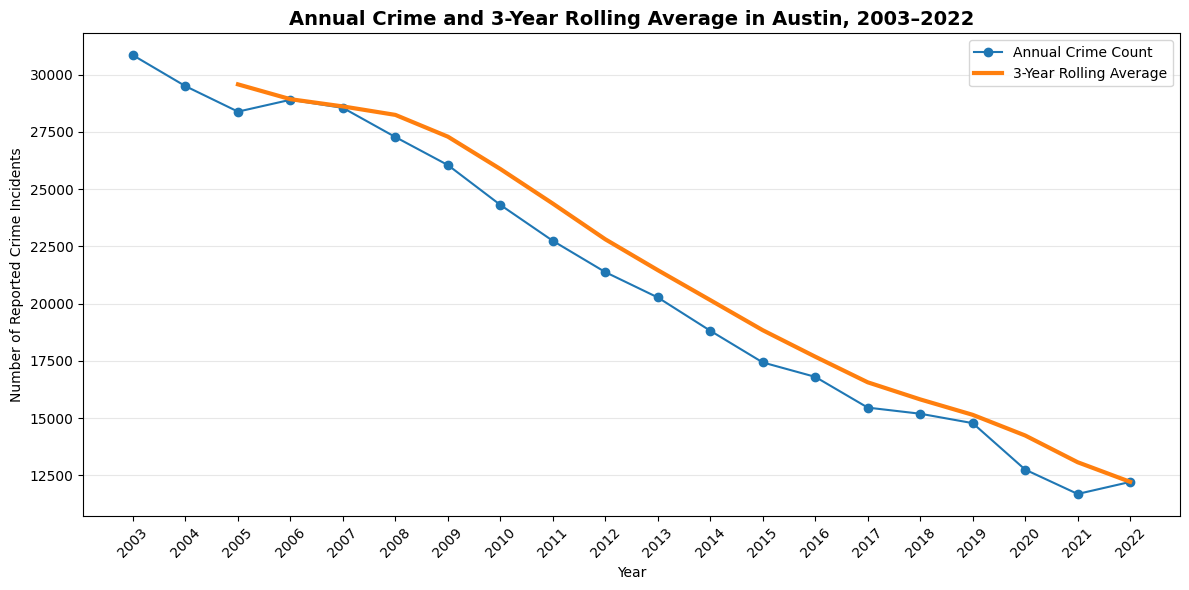

Figure saved to: C:\Users\USER\Desktop\Masters\Big Enterprise\DAS7002\outputs\figures\task2_austin_3year_rolling_average_2003_2022.png


In [41]:
austin_rolling_pd = austin_rolling_df.toPandas()

plt.figure(figsize=(12, 6))

plt.plot(
    austin_rolling_pd["Year"],
    austin_rolling_pd["Annual_Crime_Count"],
    marker="o",
    linewidth=1.5,
    label="Annual Crime Count"
)

plt.plot(
    austin_rolling_pd["Year"],
    austin_rolling_pd["Rolling_3Year_Avg_Complete"],
    linewidth=3,
    label="3-Year Rolling Average"
)

plt.title(
    "Annual Crime and 3-Year Rolling Average in Austin, 2003–2022",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Year")
plt.ylabel("Number of Reported Crime Incidents")

plt.xticks(
    austin_rolling_pd["Year"],
    rotation=45
)

plt.legend()

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

AUSTIN_ROLLING_FIGURE_PATH = (
    FIGURES_DIR / "task2_austin_3year_rolling_average_2003_2022.png"
)

plt.savefig(
    AUSTIN_ROLLING_FIGURE_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure saved to:", AUSTIN_ROLLING_FIGURE_PATH)

### 5.2.4 Rolling Average Interpretation

The three-year rolling average confirms a substantial long-term decline in reported crime within Austin.

The first complete rolling average, calculated for 2005, is approximately 29,570 incidents. This falls progressively across the study period and reaches approximately 12,216 incidents by 2022.

The smoothed series removes much of the year-to-year fluctuation visible in the annual counts and demonstrates that the decline is persistent rather than being driven by isolated individual years.

Although the annual crime count increases slightly between 2021 and 2022, the three-year rolling average remains close to its lowest level in the series, indicating that the broader downward trend is still evident.

This analysis describes changes in reported incident volume within Austin and should not be interpreted as a population-adjusted crime rate because annual community-area population denominators are not included in the available datasets.

## 6. Weather and Crime Relationship

Weather conditions are examined alongside daily reported crime volumes to investigate whether crime activity varies with temperature, precipitation, and snowfall.

Because the weather dataset contains one observation per day, the crime dataset is first aggregated to daily incident counts. The resulting daily crime series is then joined to the cleaned Chicago Midway weather dataset using calendar date.

This preserves a consistent daily level of analysis and avoids incorrectly joining individual crime records directly to repeated weather observations.

In [42]:
daily_crime_df = (
    crime_enriched_df
    .filter(
        (F.col("Year") >= 2003) &
        (F.col("Year") <= 2022) &
        F.col("Crime_Date").isNotNull()
    )
    .groupBy("Crime_Date")
    .agg(
        F.count("*").alias("Daily_Crime_Count")
    )
)

daily_crime_df.orderBy("Crime_Date").show(10, truncate=False)

+----------+-----------------+
|Crime_Date|Daily_Crime_Count|
+----------+-----------------+
|2003-01-01|2033             |
|2003-01-02|1171             |
|2003-01-03|1298             |
|2003-01-04|1197             |
|2003-01-05|1149             |
|2003-01-06|1261             |
|2003-01-07|1203             |
|2003-01-08|1318             |
|2003-01-09|1317             |
|2003-01-10|1232             |
+----------+-----------------+
only showing top 10 rows



In [43]:
print(
    "Daily crime observations:",
    daily_crime_df.count()
)

Daily crime observations: 7305


In [44]:
weather_df.printSchema()

root
 |-- STATION: string (nullable = true)
 |-- NAME: string (nullable = true)
 |-- Weather_Date: date (nullable = true)
 |-- AWND: double (nullable = true)
 |-- PRCP: double (nullable = true)
 |-- SNOW: double (nullable = true)
 |-- SNWD: double (nullable = true)
 |-- TMAX: double (nullable = true)
 |-- TMIN: double (nullable = true)
 |-- Has_Precipitation: boolean (nullable = true)
 |-- Has_Snowfall: boolean (nullable = true)
 |-- Mean_Temperature: double (nullable = true)
 |-- Temperature_Range: double (nullable = true)



In [45]:
weather_df.select(
    "Weather_Date",
    "Mean_Temperature",
    "PRCP",
    "Has_Precipitation",
    "SNOW",
    "Has_Snowfall"
).show(10, truncate=False)

+------------+----------------+----+-----------------+----+------------+
|Weather_Date|Mean_Temperature|PRCP|Has_Precipitation|SNOW|Has_Snowfall|
+------------+----------------+----+-----------------+----+------------+
|2001-01-01  |19.5            |0.0 |false            |NULL|NULL        |
|2001-01-02  |13.5            |0.0 |false            |NULL|NULL        |
|2001-01-03  |17.5            |0.0 |false            |NULL|NULL        |
|2001-01-04  |27.5            |0.0 |false            |NULL|NULL        |
|2001-01-05  |29.5            |0.0 |false            |0.0 |false       |
|2001-01-06  |27.5            |0.0 |false            |0.0 |false       |
|2001-01-07  |29.0            |0.0 |false            |NULL|NULL        |
|2001-01-08  |23.0            |0.0 |false            |NULL|NULL        |
|2001-01-09  |18.5            |0.0 |false            |NULL|NULL        |
|2001-01-10  |27.5            |0.0 |false            |NULL|NULL        |
+------------+----------------+----+---------------

### 6.1 Joining Daily Crime and Weather Data

The daily crime series is joined to the cleaned Chicago Midway weather dataset using the calendar date.

A left join is used so that all observed crime dates are retained even if a weather observation is unavailable for a particular day. This is important because the weather dataset contains a very small number of missing calendar dates identified during Task 1.

In [46]:
daily_weather_crime_df = (
    daily_crime_df
    .join(
        weather_df,
        daily_crime_df["Crime_Date"] == weather_df["Weather_Date"],
        "left"
    )
    .drop("Weather_Date")
)

print("Daily crime-weather join completed.")

Daily crime-weather join completed.


In [47]:
daily_weather_validation = (
    daily_weather_crime_df
    .agg(
        F.count("*").alias("Total_Daily_Records"),
        F.sum(
            F.when(F.col("Mean_Temperature").isNull(), 1).otherwise(0)
        ).alias("Missing_Mean_Temperature"),
        F.sum(
            F.when(F.col("PRCP").isNull(), 1).otherwise(0)
        ).alias("Missing_Precipitation")
    )
)

daily_weather_validation.show(truncate=False)

+-------------------+------------------------+---------------------+
|Total_Daily_Records|Missing_Mean_Temperature|Missing_Precipitation|
+-------------------+------------------------+---------------------+
|7305               |2                       |14                   |
+-------------------+------------------------+---------------------+



In [48]:
daily_weather_crime_df.select(
    "Crime_Date",
    "Daily_Crime_Count",
    "Mean_Temperature",
    "PRCP",
    "Has_Precipitation",
    "SNOW",
    "Has_Snowfall"
).orderBy("Crime_Date").show(15, truncate=False)

+----------+-----------------+----------------+----+-----------------+----+------------+
|Crime_Date|Daily_Crime_Count|Mean_Temperature|PRCP|Has_Precipitation|SNOW|Has_Snowfall|
+----------+-----------------+----------------+----+-----------------+----+------------+
|2003-01-01|2033             |32.0            |0.0 |false            |NULL|NULL        |
|2003-01-02|1171             |29.5            |0.0 |false            |NULL|NULL        |
|2003-01-03|1298             |29.5            |0.0 |false            |NULL|NULL        |
|2003-01-04|1197             |26.5            |0.04|true             |NULL|NULL        |
|2003-01-05|1149             |31.5            |0.05|true             |NULL|NULL        |
|2003-01-06|1261             |29.5            |0.01|true             |NULL|NULL        |
|2003-01-07|1203             |39.5            |0.0 |false            |NULL|NULL        |
|2003-01-08|1318             |45.5            |0.0 |false            |NULL|NULL        |
|2003-01-09|1317     

### 6.2 Temperature and Crime Correlation

The relationship between daily mean temperature and daily reported crime volume is evaluated using Pearson correlation.

Only days with observed mean temperature values are included in the correlation calculation. Missing weather values are excluded rather than imputed so that the analysis remains based on observed measurements.

In [49]:
temperature_correlation = (
    daily_weather_crime_df
    .filter(
        F.col("Mean_Temperature").isNotNull()
    )
    .stat.corr(
        "Mean_Temperature",
        "Daily_Crime_Count"
    )
)

print(
    f"Pearson correlation between mean temperature "
    f"and daily crime count: {temperature_correlation:.4f}"
)

Pearson correlation between mean temperature and daily crime count: 0.2542


### 6.3 Crime on Precipitation and Non-Precipitation Days

Daily crime volumes are compared between days with measurable precipitation and days without precipitation.

The comparison uses only records where precipitation measurements are available.

In [50]:
precipitation_crime_summary = (
    daily_weather_crime_df
    .filter(
        F.col("PRCP").isNotNull()
    )
    .groupBy("Has_Precipitation")
    .agg(
        F.count("*").alias("Number_of_Days"),
        F.round(
            F.avg("Daily_Crime_Count"),
            2
        ).alias("Average_Daily_Crime"),
        F.min("Daily_Crime_Count").alias("Minimum_Daily_Crime"),
        F.max("Daily_Crime_Count").alias("Maximum_Daily_Crime")
    )
    .orderBy("Has_Precipitation")
)

precipitation_crime_summary.show(truncate=False)

+-----------------+--------------+-------------------+-------------------+-------------------+
|Has_Precipitation|Number_of_Days|Average_Daily_Crime|Minimum_Daily_Crime|Maximum_Daily_Crime|
+-----------------+--------------+-------------------+-------------------+-------------------+
|false            |4843          |928.39             |341                |2033               |
|true             |2448          |911.82             |320                |1978               |
+-----------------+--------------+-------------------+-------------------+-------------------+



### 6.4 Precipitation Amount and Crime Correlation

In addition to comparing precipitation and non-precipitation days, the relationship between measured precipitation amount and daily crime volume is assessed using Pearson correlation.

In [51]:
precipitation_correlation = (
    daily_weather_crime_df
    .filter(
        F.col("PRCP").isNotNull()
    )
    .stat.corr(
        "PRCP",
        "Daily_Crime_Count"
    )
)

print(
    f"Pearson correlation between precipitation "
    f"and daily crime count: {precipitation_correlation:.4f}"
)

Pearson correlation between precipitation and daily crime count: -0.0259


### 6.5 Weather Relationship Interpretation

The weather analysis identifies a weak positive association between temperature and daily reported crime.

Mean daily temperature has a Pearson correlation of 0.2542 with daily crime volume. This indicates that warmer days are generally associated with somewhat higher numbers of reported incidents, although the relationship is not sufficiently strong to suggest that temperature alone explains changes in crime activity.

The precipitation analysis shows a much weaker relationship. Days without measurable precipitation record an average of 928.39 incidents, compared with 911.82 incidents on precipitation days.

The Pearson correlation between precipitation amount and daily crime volume is -0.0259, indicating virtually no linear relationship between rainfall quantity and reported crime.

These findings are observational and do not establish a causal effect of weather on crime. Other temporal, behavioural, socioeconomic, and spatial factors may influence both crime patterns and the observed associations.

### 6.6 Snowfall Data Limitation

Snowfall is not used as a primary explanatory variable because the NOAA source contains substantial missingness in the `SNOW` field.

Treating missing snowfall measurements as zero would incorrectly assume that no snow occurred on unobserved days. Therefore, snowfall is retained in the processed dataset but excluded from the main correlation analysis to avoid introducing unsupported assumptions.

## 7. Socioeconomic Factors and Community Crime

Community-level crime totals are joined with the socioeconomic indicators prepared in Task 1 to examine whether crime volume is associated with poverty, per-capita income, and hardship.

Because the socioeconomic dataset contains one observation per community area, the crime dataset is first aggregated to the same community-area level before the relationship is assessed.

In [52]:
socio_df.printSchema()

root
 |-- Community_Area: integer (nullable = true)
 |-- Community_Name: string (nullable = true)
 |-- Poverty_Percent: double (nullable = true)
 |-- Per_Capita_Income: integer (nullable = true)
 |-- Hardship_Index: integer (nullable = true)



In [53]:
socio_df.show(10, truncate=False)

+--------------+---------------+---------------+-----------------+--------------+
|Community_Area|Community_Name |Poverty_Percent|Per_Capita_Income|Hardship_Index|
+--------------+---------------+---------------+-----------------+--------------+
|1             |Rogers Park    |23.6           |23939            |39            |
|2             |West Ridge     |17.2           |23040            |46            |
|3             |Uptown         |24.0           |35787            |20            |
|4             |Lincoln Square |10.9           |37524            |17            |
|5             |North Center   |7.5            |57123            |6             |
|6             |Lake View      |11.4           |60058            |5             |
|7             |Lincoln Park   |12.3           |71551            |2             |
|8             |Near North Side|12.9           |88669            |1             |
|9             |Edison Park    |3.3            |40959            |8             |
|10            |

In [54]:
community_crime_2003_2022_df = spark.sql("""
    SELECT
        `Community Area` AS Community_Area,
        Community_Name,
        COUNT(*) AS Crime_Count
    FROM crime_enriched
    WHERE Year BETWEEN 2003 AND 2022
      AND Community_Name IS NOT NULL
    GROUP BY
        `Community Area`,
        Community_Name
""")

print(
    "Community areas in crime summary:",
    community_crime_2003_2022_df.count()
)

Community areas in crime summary: 77


In [55]:
community_socio_df = (
    community_crime_2003_2022_df
    .join(
        socio_df,
        "Community_Area",
        "inner"
    )
)

print(
    "Community areas after socioeconomic join:",
    community_socio_df.count()
)

Community areas after socioeconomic join: 77


In [56]:
community_socio_df.show(
    10,
    truncate=False
)

+--------------+---------------+-----------+---------------+---------------+-----------------+--------------+
|Community_Area|Community_Name |Crime_Count|Community_Name |Poverty_Percent|Per_Capita_Income|Hardship_Index|
+--------------+---------------+-----------+---------------+---------------+-----------------+--------------+
|56            |GARFIELD RIDGE |54837      |Garfield Ridge |8.8            |26353            |32            |
|58            |BRIGHTON PARK  |65038      |Brighton Park  |23.6           |13089            |84            |
|2             |WEST RIDGE     |86560      |West Ridge     |17.2           |23040            |46            |
|28            |NEAR WEST SIDE |203118     |Near West Side |20.6           |44689            |15            |
|52            |EAST SIDE      |33318      |East Side      |19.2           |17104            |64            |
|33            |NEAR SOUTH SIDE|51985      |Near South Side|13.8           |59077            |7             |
|66       

### 7.1 Socioeconomic Join Validation

All 77 Chicago community areas are retained after joining the crime summary with the socioeconomic dataset, confirming complete community-level coverage.

Because both source datasets contain a community name field, the joined dataset is cleaned to retain a single community-name column before correlation analysis.

In [57]:
community_socio_df = (
    community_crime_2003_2022_df.alias("crime")
    .join(
        socio_df.alias("socio"),
        F.col("crime.Community_Area") ==
        F.col("socio.Community_Area"),
        "inner"
    )
    .select(
        F.col("crime.Community_Area").alias("Community_Area"),
        F.col("crime.Community_Name").alias("Community_Name"),
        F.col("crime.Crime_Count").alias("Crime_Count"),
        F.col("socio.Poverty_Percent").alias("Poverty_Percent"),
        F.col("socio.Per_Capita_Income").alias("Per_Capita_Income"),
        F.col("socio.Hardship_Index").alias("Hardship_Index")
    )
)

community_socio_df.show(10, truncate=False)

+--------------+---------------+-----------+---------------+-----------------+--------------+
|Community_Area|Community_Name |Crime_Count|Poverty_Percent|Per_Capita_Income|Hardship_Index|
+--------------+---------------+-----------+---------------+-----------------+--------------+
|56            |GARFIELD RIDGE |54837      |8.8            |26353            |32            |
|58            |BRIGHTON PARK  |65038      |23.6           |13089            |84            |
|2             |WEST RIDGE     |86560      |17.2           |23040            |46            |
|28            |NEAR WEST SIDE |203118     |20.6           |44689            |15            |
|52            |EAST SIDE      |33318      |19.2           |17104            |64            |
|33            |NEAR SOUTH SIDE|51985      |13.8           |59077            |7             |
|66            |CHICAGO LAWN   |164848     |27.9           |13231            |80            |
|57            |ARCHER HEIGHTS |24328      |14.1           |

### 7.2 Socioeconomic Correlation Analysis

Pearson correlation is used to assess the linear relationship between cumulative reported crime volume and three socioeconomic indicators:

- percentage of households below poverty,
- per-capita income,
- hardship index.

The analysis is conducted across Chicago's 77 community areas using crime records from 2003–2022.

In [58]:
poverty_corr = community_socio_df.stat.corr(
    "Poverty_Percent",
    "Crime_Count"
)

income_corr = community_socio_df.stat.corr(
    "Per_Capita_Income",
    "Crime_Count"
)

hardship_corr = community_socio_df.stat.corr(
    "Hardship_Index",
    "Crime_Count"
)

print(
    f"Poverty % vs Crime Count correlation: "
    f"{poverty_corr:.4f}"
)

print(
    f"Per-Capita Income vs Crime Count correlation: "
    f"{income_corr:.4f}"
)

print(
    f"Hardship Index vs Crime Count correlation: "
    f"{hardship_corr:.4f}"
)

Poverty % vs Crime Count correlation: 0.2953
Per-Capita Income vs Crime Count correlation: 0.0387
Hardship Index vs Crime Count correlation: 0.1651


In [59]:
socio_correlation_df = spark.sql(f"""
    SELECT
        'Poverty_Percent' AS Socioeconomic_Factor,
        {poverty_corr} AS Pearson_Correlation

    UNION ALL

    SELECT
        'Per_Capita_Income',
        {income_corr}

    UNION ALL

    SELECT
        'Hardship_Index',
        {hardship_corr}
""")

socio_correlation_df = (
    socio_correlation_df
    .withColumn(
        "Pearson_Correlation",
        F.round("Pearson_Correlation", 4)
    )
)

socio_correlation_df.show(truncate=False)

+--------------------+-------------------+
|Socioeconomic_Factor|Pearson_Correlation|
+--------------------+-------------------+
|Poverty_Percent     |0.2953             |
|Per_Capita_Income   |0.0387             |
|Hardship_Index      |0.1651             |
+--------------------+-------------------+



### 7.3 Socioeconomic Correlation Interpretation

The strongest of the three socioeconomic relationships is observed between poverty and cumulative reported crime, with a Pearson correlation of 0.2953. This represents a weak positive linear association, indicating that community areas with higher poverty percentages tend to record somewhat higher crime volumes.

The Hardship Index also has a positive relationship with crime volume, although the correlation is weaker at 0.1651.

In contrast, per-capita income has a correlation of only 0.0387 with cumulative crime volume, indicating almost no linear relationship within this community-level analysis.

These correlations should be interpreted cautiously. The dependent measure is cumulative incident volume rather than a population-normalised crime rate. Community areas differ in population, commercial activity, land use, and daily population movement, meaning that higher crime counts do not necessarily imply greater individual crime risk.

Furthermore, correlation does not establish that socioeconomic conditions cause crime. The results identify statistical associations across community areas rather than causal relationships.

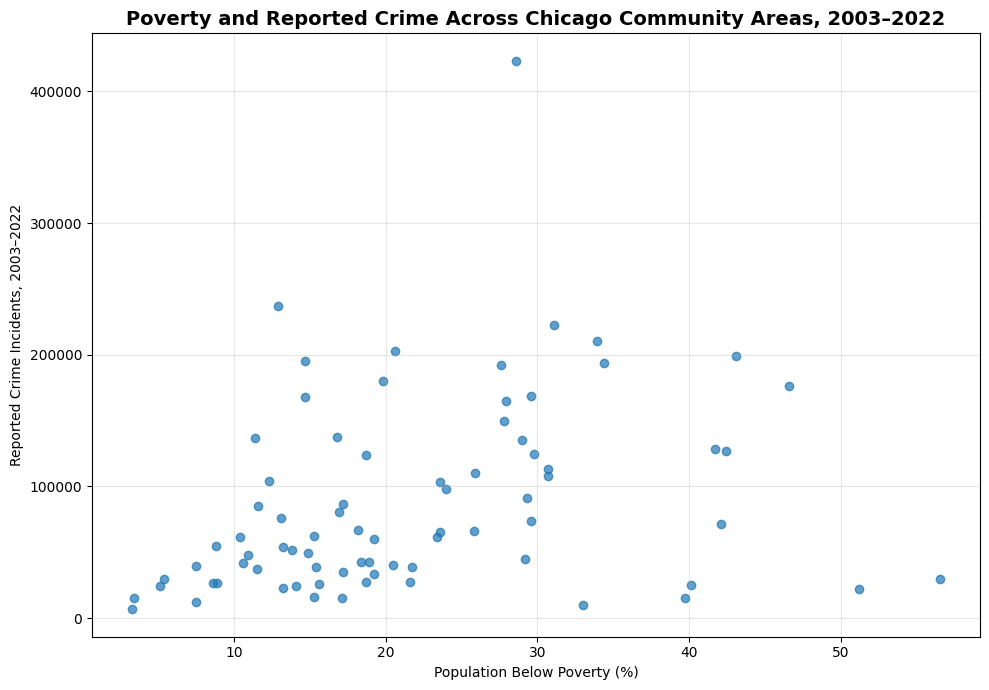

Figure saved to: C:\Users\USER\Desktop\Masters\Big Enterprise\DAS7002\outputs\figures\task2_poverty_vs_crime_community_areas.png


In [60]:
poverty_plot_pd = (
    community_socio_df
    .select(
        "Community_Name",
        "Poverty_Percent",
        "Crime_Count"
    )
    .toPandas()
)

plt.figure(figsize=(10, 7))

plt.scatter(
    poverty_plot_pd["Poverty_Percent"],
    poverty_plot_pd["Crime_Count"],
    alpha=0.7
)

plt.title(
    "Poverty and Reported Crime Across Chicago Community Areas, 2003–2022",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Population Below Poverty (%)")
plt.ylabel("Reported Crime Incidents, 2003–2022")

plt.grid(alpha=0.3)
plt.tight_layout()

POVERTY_FIGURE_PATH = (
    FIGURES_DIR / "task2_poverty_vs_crime_community_areas.png"
)

plt.savefig(
    POVERTY_FIGURE_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure saved to:", POVERTY_FIGURE_PATH)

### 7.4 Poverty–Crime Relationship Interpretation

The scatter plot supports the Pearson correlation result of 0.2953, showing a weak positive relationship between poverty percentage and cumulative reported crime across Chicago community areas.

Community areas with higher poverty levels tend, on average, to appear at higher crime volumes, but the substantial dispersion of observations indicates that poverty alone does not explain the spatial distribution of reported crime.

Several community areas depart noticeably from the general pattern, demonstrating that areas with similar poverty levels can experience substantially different incident volumes. This suggests that other characteristics, including population size, land use, commercial activity, mobility, and broader socioeconomic conditions, may contribute to the observed spatial variation.

The analysis therefore provides evidence of association rather than causation and should not be interpreted as a population-adjusted measure of individual crime risk.

## 8. Distribution of Major Crime Types

The categorical composition of reported crime is examined using `Primary Type`.

Crime categories are aggregated across complete years from 2001–2022 to identify the most frequently reported offence types in the dataset.

In [61]:
primary_type_df = spark.sql("""
    SELECT
        `Primary Type` AS Primary_Type,
        COUNT(*) AS Crime_Count
    FROM crime_enriched
    WHERE Year BETWEEN 2001 AND 2022
      AND `Primary Type` IS NOT NULL
    GROUP BY `Primary Type`
    ORDER BY Crime_Count DESC
""")

primary_type_df.show(20, truncate=False)

+--------------------------------+-----------+
|Primary_Type                    |Crime_Count|
+--------------------------------+-----------+
|THEFT                           |1626890    |
|BATTERY                         |1410849    |
|CRIMINAL DAMAGE                 |878902     |
|NARCOTICS                       |746044     |
|ASSAULT                         |501090     |
|OTHER OFFENSE                   |478979     |
|BURGLARY                        |422245     |
|MOTOR VEHICLE THEFT             |366564     |
|DECEPTIVE PRACTICE              |340232     |
|ROBBERY                         |289680     |
|CRIMINAL TRESPASS               |212863     |
|WEAPONS VIOLATION               |103900     |
|PROSTITUTION                    |69750      |
|OFFENSE INVOLVING CHILDREN      |55113      |
|PUBLIC PEACE VIOLATION          |52083      |
|SEX OFFENSE                     |30322      |
|CRIM SEXUAL ASSAULT             |27631      |
|INTERFERENCE WITH PUBLIC OFFICER|18204      |
|LIQUOR LAW V

In [62]:
print(
    "Number of distinct Primary Type categories:",
    primary_type_df.count()
)

Number of distinct Primary Type categories: 36


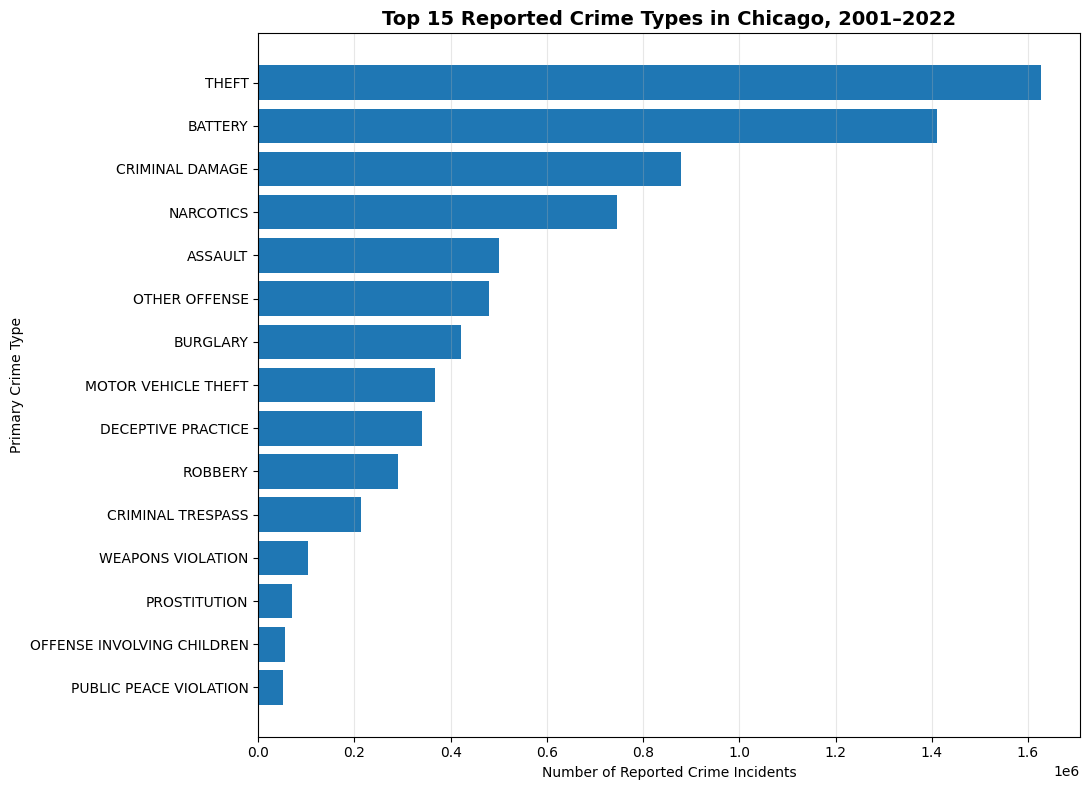

Figure saved to: C:\Users\USER\Desktop\Masters\Big Enterprise\DAS7002\outputs\figures\task2_top15_primary_crime_types_2001_2022.png


In [63]:
top_15_type_pd = (
    primary_type_df
    .orderBy(F.desc("Crime_Count"))
    .limit(15)
    .toPandas()
)

plt.figure(figsize=(11, 8))

plt.barh(
    top_15_type_pd["Primary_Type"][::-1],
    top_15_type_pd["Crime_Count"][::-1]
)

plt.title(
    "Top 15 Reported Crime Types in Chicago, 2001–2022",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Number of Reported Crime Incidents")
plt.ylabel("Primary Crime Type")

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()

CRIME_TYPE_FIGURE_PATH = (
    FIGURES_DIR / "task2_top15_primary_crime_types_2001_2022.png"
)

plt.savefig(
    CRIME_TYPE_FIGURE_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "Figure saved to:",
    CRIME_TYPE_FIGURE_PATH
)

### 8.1 Crime-Type Distribution Interpretation

The distribution of reported crime is strongly concentrated in a relatively small number of offence categories.

Theft is the most frequently recorded primary crime type, with 1,626,890 incidents between 2001 and 2022, followed by Battery with 1,410,849 incidents. Criminal Damage and Narcotics also account for substantial volumes, with 878,902 and 746,044 incidents respectively.

In total, the dataset contains 36 distinct primary crime categories. However, the top categories account for a disproportionately large share of all reported incidents, indicating substantial class imbalance across crime types.

The concentration of incidents across a relatively small number of offence categories is an important descriptive characteristic of the dataset.

Although `Primary Type` is not used as the prediction target in Task 4, its uneven distribution remains relevant because offence type is included as a predictor in the arrest-classification model. Highly frequent offence categories may therefore have greater influence on learned model patterns than rare categories.

The later supervised-learning analysis separately evaluates class imbalance in the binary `Arrest` target using precision, recall, F1-score, ROC-AUC, and PR-AUC rather than relying on accuracy alone.

## 9. Task 2 Summary and Validation

Task 2 used Spark SQL, DataFrame operations, broadcast joins, window functions, aggregation, and correlation analysis to investigate temporal, spatial, weather, socioeconomic, and categorical patterns in the Chicago crime dataset.

Key findings include:

- Reported crime declined substantially across the study period, with annual crime volume in 2022 approximately 51% lower than in 2001.
- Crime displays clear seasonality, with higher volumes during warmer months and lower volumes during winter.
- Daily crime activity varies by hour, with lower activity during early-morning hours and higher activity during afternoon and evening periods.
- Crime is spatially concentrated across community areas, with Austin recording the highest cumulative incident volume.
- Community-area analysis required exclusion of 2001 and 2002 because spatial coverage was incomplete in those years.
- The three-year rolling average for Austin shows a sustained long-term decline in reported crime.
- Mean temperature has a weak positive correlation with daily crime volume, while precipitation shows almost no linear relationship.
- Poverty shows the strongest socioeconomic correlation with crime volume among the tested indicators, although the relationship remains weak.
- Crime-category frequencies are strongly imbalanced, with Theft and Battery representing the largest offence groups.
- A broadcast join successfully enriched the large crime dataset with the 77-row community lookup, demonstrating an efficient distributed join strategy.

The analysis consistently distinguishes association from causation and recognises that cumulative incident counts are not equivalent to population-adjusted crime risk.

In [64]:
print("TASK 2 FINAL VALIDATION")
print("-" * 50)

print("Crime records analysed:",
      f"{crime_enriched_df.count():,}")

print("Community areas:",
      community_socio_df.count())

print("Daily crime-weather observations:",
      daily_weather_crime_df.count())

print("Primary crime categories:",
      primary_type_df.count())

print("Temperature correlation:",
      round(temperature_correlation, 4))

print("Precipitation correlation:",
      round(precipitation_correlation, 4))

print("Poverty correlation:",
      round(poverty_corr, 4))

print("Per-capita income correlation:",
      round(income_corr, 4))

print("Hardship correlation:",
      round(hardship_corr, 4))

print("-" * 50)
print("Task 2 EDA completed successfully.")

TASK 2 FINAL VALIDATION
--------------------------------------------------
Crime records analysed: 7,784,664
Community areas: 77
Daily crime-weather observations: 7305
Primary crime categories: 36
Temperature correlation: 0.2542
Precipitation correlation: -0.0259
Poverty correlation: 0.2953
Per-capita income correlation: 0.0387
Hardship correlation: 0.1651
--------------------------------------------------
Task 2 EDA completed successfully.
